<div style="background: linear-gradient(120deg, #102b43 0%, #174d5b 58%, #1c716d 100%); color: #ffffff; border-radius: 20px; padding: 36px 40px; margin: 4px 0 28px 0;">
  <div style="font: 700 12px/1.4 Arial, sans-serif; letter-spacing: 0.18em; color: #bce9e1;">CHEMINFORMATICS · HANDS-ON NOTEBOOK</div>
  <h1 style="font: 700 42px/1.12 Arial, sans-serif; color: #ffffff; margin: 15px 0 10px 0;">From a SMILES to a molecule</h1>
  <p style="font: 18px/1.55 Arial, sans-serif; color: #e2f1f0; margin: 0;">Read a structure, ask chemical questions, and explore what changes when it becomes data.</p>
</div>

![The route from a SMILES to properties and 3D](data/images/intro_cheminformatics_workflow.svg)

Imagine receiving a spreadsheet of compounds from a colleague. Before calculating anything, you would want to recognize the structures, check what the computer has read, and decide which questions are worth asking. We will follow that same route: start with a molecule you can see, look inside its atoms and bonds, calculate a few properties, use those properties in a collection, and explore a 3D shape.

Run the cells from top to bottom with the accompanying data folder beside the notebook. The exercises are opportunities to pause and try the same reasoning with another molecule; suggested solutions are at the end.

The first cell loads RDKit, pandas, and the tools for the interactive drawings. If an import is missing, install the required packages in this notebook's environment with <code>%pip install rdkit pandas ipywidgets py3Dmol</code>, then restart the kernel and run again. The SMILES panel requires a notebook frontend with widget support.


In [34]:
# Use the same tools throughout, from the first drawing to the final 3D view.
# %pip install py3Dmol
from pathlib import Path
import pandas as pd
import py3Dmol
from IPython.display import display
from rdkit import Chem, rdBase
from rdkit.Chem import AllChem, Descriptors, Draw

## 1. Start with a structure you can see

<div style="border-left: 6px solid #2b7d86; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #2b7d86;">SMILES → DRAWING</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Try a molecule, inspect the drawing, and connect the text to the chemistry.</div>
</div>


### Your first SMILES viewer

A SMILES string is a compact way to write atoms and their connections. Before learning the details of the notation, try reading it through a drawing. Run the cell below, type a SMILES in the box, and click **Draw molecule**. Start with ethanol, CCO, then try acetic acid, CC(=O)O, or benzene, c1ccccc1.

The panel checks the input before drawing. If a string is empty or cannot be interpreted, it explains what went wrong so you can correct it. You can use this panel again whenever a later example introduces a new structure; you do not need to change the interface code.


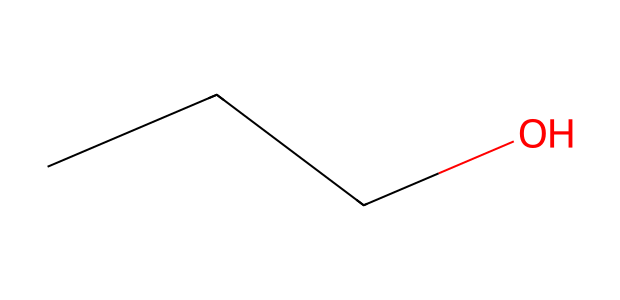

In [35]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

mol = Chem.MolFromSmiles("CCCO")
display(Draw.MolToImage(mol, size=(620, 300)))


When RDKit reads a SMILES string, hydrogen atoms are usually handled implicitly. This means RDKit knows how many hydrogens belong to each atom based on its valence, without storing them as separate atoms in the molecular graph.

For many operations, such as drawing 2D structures or calculating molecular descriptors, implicit hydrogens are sufficient.

However, for 3D conformer generation and force-field optimization, we generally add hydrogen atoms explicitly. This allows RDKit to assign individual 3D coordinates to each hydrogen and account for their contributions to molecular geometry and energy.

We can use Chem.AddHs() to convert implicit hydrogens into actual hydrogen atoms in the molecular graph.

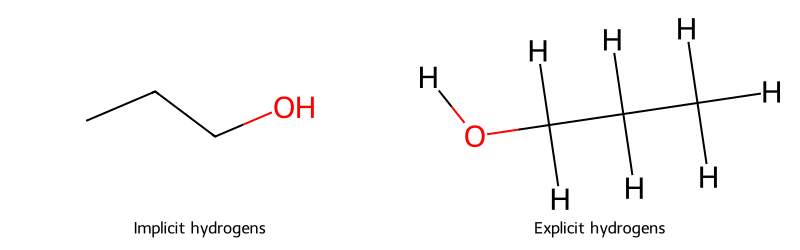

Atoms with implicit H: 4
Atoms with explicit H: 12


In [36]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

# STEP 1 — Read the molecule from a SMILES string

mol = Chem.MolFromSmiles("CCCO")  # 1-propanol

# STEP 2 — Add explicit hydrogen atoms
# Each hydrogen becomes an individual atom in the molecular graph.
# The original molecule remains unchanged.

mol_with_h = Chem.AddHs(mol)

# STEP 3 — Compare both representations
display(
    Draw.MolsToGridImage(
        [mol, mol_with_h],
        legends=["Implicit hydrogens", "Explicit hydrogens"],
        molsPerRow=2,
        subImgSize=(400, 250)
    )
)

# STEP 4 — Compare the number of atoms
print(f"Atoms with implicit H: {mol.GetNumAtoms()}")
print(f"Atoms with explicit H: {mol_with_h.GetNumAtoms()}")

## 2. Look inside the molecule

<div style="border-left: 6px solid #2b7d86; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #2b7d86;">ATOMS, BONDS, AND RINGS</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Use a familiar drawing to understand the molecular graph behind it.</div>
</div>


### From text to atoms and bonds

The viewer turns text into an RDKit **Mol** object. This object stores a molecular graph: atoms and the bonds that connect them, along with chemical information such as charges and bond types. It can later hold coordinates too, but parsing a SMILES does not generate a 3D conformer.

The **degree** is the number of directly bonded atom objects; it therefore depends on whether hydrogens have been made explicit. It is not the sum of bond orders.

In [37]:
# Follow each atom in the explicit-hydrogen graph.
mol = Chem.MolFromSmiles("CC=C")

for atom in mol.GetAtoms():
    print(f"Atom {atom.GetIdx()}: {atom.GetSymbol()} (degree = {atom.GetDegree()})")

Atom 0: C (degree = 1)
Atom 1: C (degree = 2)
Atom 2: C (degree = 1)


The index is RDKit's label for an atom in this particular representation. It gives us a way to return to one atom without drawing the molecule again. Here we select index 1 and inspect the same information. These indices are not permanent identifiers across different molecules or atom orderings.


In [38]:
# Retrieve one atom from the same graph used above.
atom = mol.GetAtomWithIdx(1)
print(f"Atom {atom.GetIdx()}: {atom.GetSymbol()} (degree = {atom.GetDegree()})")

Atom 1: C (degree = 2)


Atoms alone do not define the structure; we also need to know which ones are connected and by what kind of bond. The next loop reads those connections. Find the carbon–carbon double bond in the output and relate it to the propene drawing.


In [39]:
# Each bond connects two atom indices and has its own bond type.
for bond in mol.GetBonds():
    begin_idx = bond.GetBeginAtomIdx()
    end_idx = bond.GetEndAtomIdx()
    begin_symbol = mol.GetAtomWithIdx(begin_idx).GetSymbol()
    end_symbol = mol.GetAtomWithIdx(end_idx).GetSymbol()
    print(
        f"Bond: {begin_idx} ({begin_symbol}) - "
        f"{end_idx} ({end_symbol}) | Type: {bond.GetBondType()}"
    )

Bond: 0 (C) - 1 (C) | Type: SINGLE
Bond: 1 (C) - 2 (C) | Type: DOUBLE


### Recognize a ring

Propene has no ring, so a ring query would give the same negative answer for every atom. Toluene makes the distinction visible: the six aromatic carbons belong to a ring, while the methyl carbon does not. We will highlight the ring atoms so the numerical result can be checked against the drawing.


Ring atom indices: [0, 1, 2, 3, 4, 5]


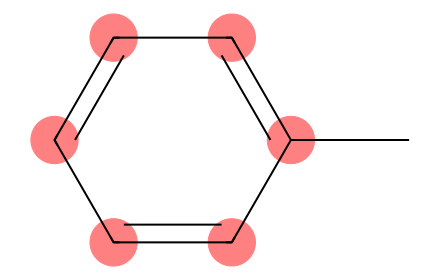

In [40]:
# Ask a graph question and make its answer visible.
mol_ring = Chem.MolFromSmiles("c1ccccc1C")
ring_atoms = [atom.GetIdx() for atom in mol_ring.GetAtoms() if atom.IsInRing()]
print("Ring atom indices:", ring_atoms)
display(Draw.MolToImage(mol_ring, highlightAtoms=ring_atoms, size=(440, 280)))

### Different strings, the same structure

A SMILES is one way of walking through a molecular graph. Starting from a different atom can give another string for the same molecule. The next three strings all describe ethanol.

RDKit can write a **canonical SMILES** using a consistent atom ordering. This helps compare entries processed with the same settings and RDKit version. It does not, by itself, make different protonation states, tautomers, or salts equivalent; those require a separate standardization decision.


CCO -> CCO
OCC -> CCO
C(O)C -> CCO


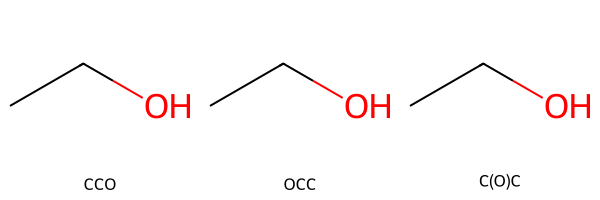

In [41]:
# Compare structures after parsing, rather than comparing their input text.
smiles_list = ["CCO", "OCC", "C(O)C"]
mols = [Chem.MolFromSmiles(text) for text in smiles_list]
for text, molecule in zip(smiles_list, mols):
    print(f"{text} -> {Chem.MolToSmiles(molecule, canonical=True)}")
display(Draw.MolsToGridImage(mols, legends=smiles_list, molsPerRow=3))

### Try the same questions yourself

Create a Mol object and find its heavy-atom count, bond count, and canonical SMILES. Compare the atom and bond counts before and after adding explicit hydrogens; state which representation each number describes.


In [42]:
# Build the structure, then check your prediction against the graph.
exercise_smiles = "CC(O)C=O"
# Your code here


## 3. Turn structures into useful numbers

<div style="border-left: 6px solid #ab6747; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #ab6747;">MOLECULAR DESCRIPTORS</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Calculate a few interpretable properties before considering a larger table.</div>
</div>


A drawing lets us recognize ethanol immediately. A descriptor turns one aspect of that structure into a number that we can sort, compare, or use in a model. Molecular weight and calculated logP answer different questions, so their meaning matters more than the number of descriptors available.

We will begin with ethanol. Molecular weight includes its hydrogens even when they are implicit. Calculated logP is an estimate of partitioning between octanol and water, not a measured solubility or a complete description of behavior in a reaction solvent.

When comparing compounds, describe their charges and protonation states consistently. These calculations use the structure you supplied; they do not work out which form is present at your experimental pH.


In [43]:
# These descriptors can be calculated directly from the ordinary molecular graph.
descriptor_mol = Chem.MolFromSmiles("CCO")
print("Molecular weight (g/mol):", round(Descriptors.MolWt(descriptor_mol), 2))
print("Calculated logP:", round(Descriptors.MolLogP(descriptor_mol), 2))
print("H-bond donors:", Descriptors.NumHDonors(descriptor_mol))
print("H-bond acceptors:", Descriptors.NumHAcceptors(descriptor_mol))


Molecular weight (g/mol): 46.07
Calculated logP: -0.0
H-bond donors: 1
H-bond acceptors: 1


### Read a property profile in context

Aspirin gives us a more interesting profile than a small hydrocarbon. We will calculate four values often discussed with Lipinski's rule of five. Hydrogen-bond acceptors and donors need chemical definitions: counting every nitrogen and oxygen is not a substitute for recognizing those roles.

The thresholds below are a screening heuristic developed in oral drug discovery. They can flag compounds worth examining more closely, but meeting them does not establish bioavailability, safety, or usefulness in another chemical setting. [Original discussion by Lipinski and colleagues](https://pubmed.ncbi.nlm.nih.gov/11259830/).


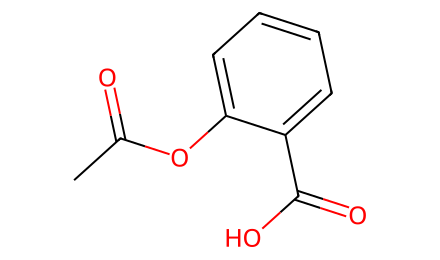

,Property,Value,Upper limit,Above limit
0,Molecular weight (g/mol),180.16,500,False
1,Calculated logP,1.31,5,False
2,H-bond donors,1.00,5,False
3,H-bond acceptors,3.00,10,False


In [44]:
# Use descriptor functions that recognize donor and acceptor chemistry.
aspirin = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")
profile = pd.DataFrame([
    {"Property": "Molecular weight (g/mol)", "Value": Descriptors.MolWt(aspirin), "Upper limit": 500},
    {"Property": "Calculated logP", "Value": Descriptors.MolLogP(aspirin), "Upper limit": 5},
    {"Property": "H-bond donors", "Value": Descriptors.NumHDonors(aspirin), "Upper limit": 5},
    {"Property": "H-bond acceptors", "Value": Descriptors.NumHAcceptors(aspirin), "Upper limit": 10},
])
profile["Above limit"] = profile["Value"] > profile["Upper limit"]
display(Draw.MolToImage(aspirin, size=(440, 260)))
display(profile.round(2))


### Try another compound

Choose a molecule from your own work or from the SMILES viewer examples. Draw it first, calculate its logP, and compare it with ethanol. Can you suggest a structural reason for the difference? Treat the value as a calculated estimate.


In [45]:
# Change the SMILES, inspect the structure, and explain the comparison.
chosen_smiles = "CC(O)C=O"
# Your code here


## 4. Use the same reasoning on a collection

<div style="border-left: 6px solid #2b7d86; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #2b7d86;">FROM ONE MOLECULE TO A TABLE</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Keep molecular identity and calculated properties together.</div>
</div>


The steps are now familiar for one molecule. A CSV lets us repeat them for a collection while retaining each compound's identifier. This example contains ethanol, benzene, and acetic acid.

Read the table as text first, then parse its SMILES column. We keep the molecule objects alongside the original rows so a result can always be traced back to its input. If a structure cannot be read, the workflow stops and identifies the affected entry rather than silently giving it a property value.


,code_name,SMILES
0,ethanol,CCO
1,benzene,c1ccccc1
2,acetic_acid,CC(=O)O


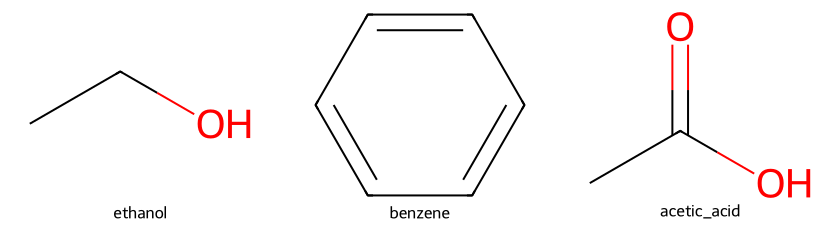

In [46]:
# Preserve each row's identifier and original SMILES during parsing.
df = pd.read_csv("data/molecules.csv")
parsed_molecules = []
for row in df.fillna("").itertuples(index=False):
    try:
        parsed_molecules.append(Chem.MolFromSmiles(row.SMILES))
    except ValueError as error:
        raise ValueError(f"Could not read {row.code_name}: {error}") from error
df["molecule"] = parsed_molecules
display(df[["code_name", "SMILES"]])
display(Draw.MolsToGridImage(
    df["molecule"].tolist(),
    legends=df["code_name"].tolist(),
    molsPerRow=3, subImgSize=(280, 230),
))

With the structures checked, we can add the same descriptors to every row. Compare ethanol with benzene and acetic acid: the table makes the differences easy to inspect, while the drawings help us interpret them.


In [47]:
# The same property definition is applied to every molecule in the collection.
df["MolWt"] = df["molecule"].apply(Descriptors.MolWt)
df["MolLogP"] = df["molecule"].apply(Descriptors.MolLogP)
df["HBD"] = df["molecule"].apply(Descriptors.NumHDonors)
df["HBA"] = df["molecule"].apply(Descriptors.NumHAcceptors)
property_table = df[["code_name", "SMILES", "MolWt", "MolLogP", "HBD", "HBA"]]
display(property_table.round(2))


,code_name,SMILES,MolWt,MolLogP,HBD,HBA
0,ethanol,CCO,46.07,-0.00,1,1
1,benzene,c1ccccc1,78.11,1.69,0,0
2,acetic_acid,CC(=O)O,60.05,0.09,1,1


We can save the identifiers, structures, and calculated values in a new CSV. A Mol object is useful inside Python; a SMILES column is more convenient when sharing the table with another tool.


In [48]:
# Export text and numbers, keeping generated results apart from the input data.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
property_table.to_csv(output_dir / "molecular_properties.csv", index=False)
print("Saved:", output_dir / "molecular_properties.csv")

Saved: outputs\molecular_properties.csv


## 5. Give the graph a shape

<div style="border-left: 6px solid #7968a5; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #7968a5;">FROM CONNECTIVITY TO 3D</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Generate one possible conformation and distinguish it from the structure itself.</div>
</div>


We can read the bonds in a drawing, but what might that molecule look like in space? Let us try **1-butanol**, CCCCO: a four-carbon chain with an OH group at one end. It is flexible, so its single bonds allow several shapes without changing which atoms are connected.

The next cell draws it in 2D and builds one 3D arrangement. We will look at the result immediately, then return to the underlying details only if you want to explore them.


In [49]:
# STEP 1 — Define the molecule
# A SMILES string describes which atoms are connected,
# but it does not specify their 3D positions.

smiles = "CCCCO"  # 1-butanol
mol = Chem.MolFromSmiles(smiles)

# STEP 2 — Add hydrogen atoms
# RDKit normally keeps hydrogens implicit.
# For 3D modeling, we need their explicit positions
# because they influence bond lengths, angles, and molecular energy.

mol_3d = Chem.AddHs(mol)

# STEP 3 — Generate an initial 3D geometry
# ETKDG creates a plausible 3D arrangement of the atoms
# based on chemical geometry and conformational preferences.

params = AllChem.ETKDGv3()
params.randomSeed = 42  # Make the result reproducible

if AllChem.EmbedMolecule(mol_3d, params) != 0:
    raise RuntimeError("Failed to generate a 3D conformer.")

# STEP 4 — Optimize the molecular geometry
# The initial 3D structure is plausible, but not necessarily
# energetically favorable.
#
# UFF is a molecular force field that adjusts atomic positions
# to reduce the molecular energy by improving bond lengths,
# bond angles, torsions, and nonbonded interactions.

if not AllChem.UFFHasAllMoleculeParams(mol_3d):
    raise RuntimeError("UFF parameters are unavailable.")

status = AllChem.UFFOptimizeMolecule(mol_3d, maxIters=500)

if status == 0:
    print("Geometry optimization converged.")
else:
    print("Geometry optimization did not converge within 500 iterations.")

Geometry optimization converged.


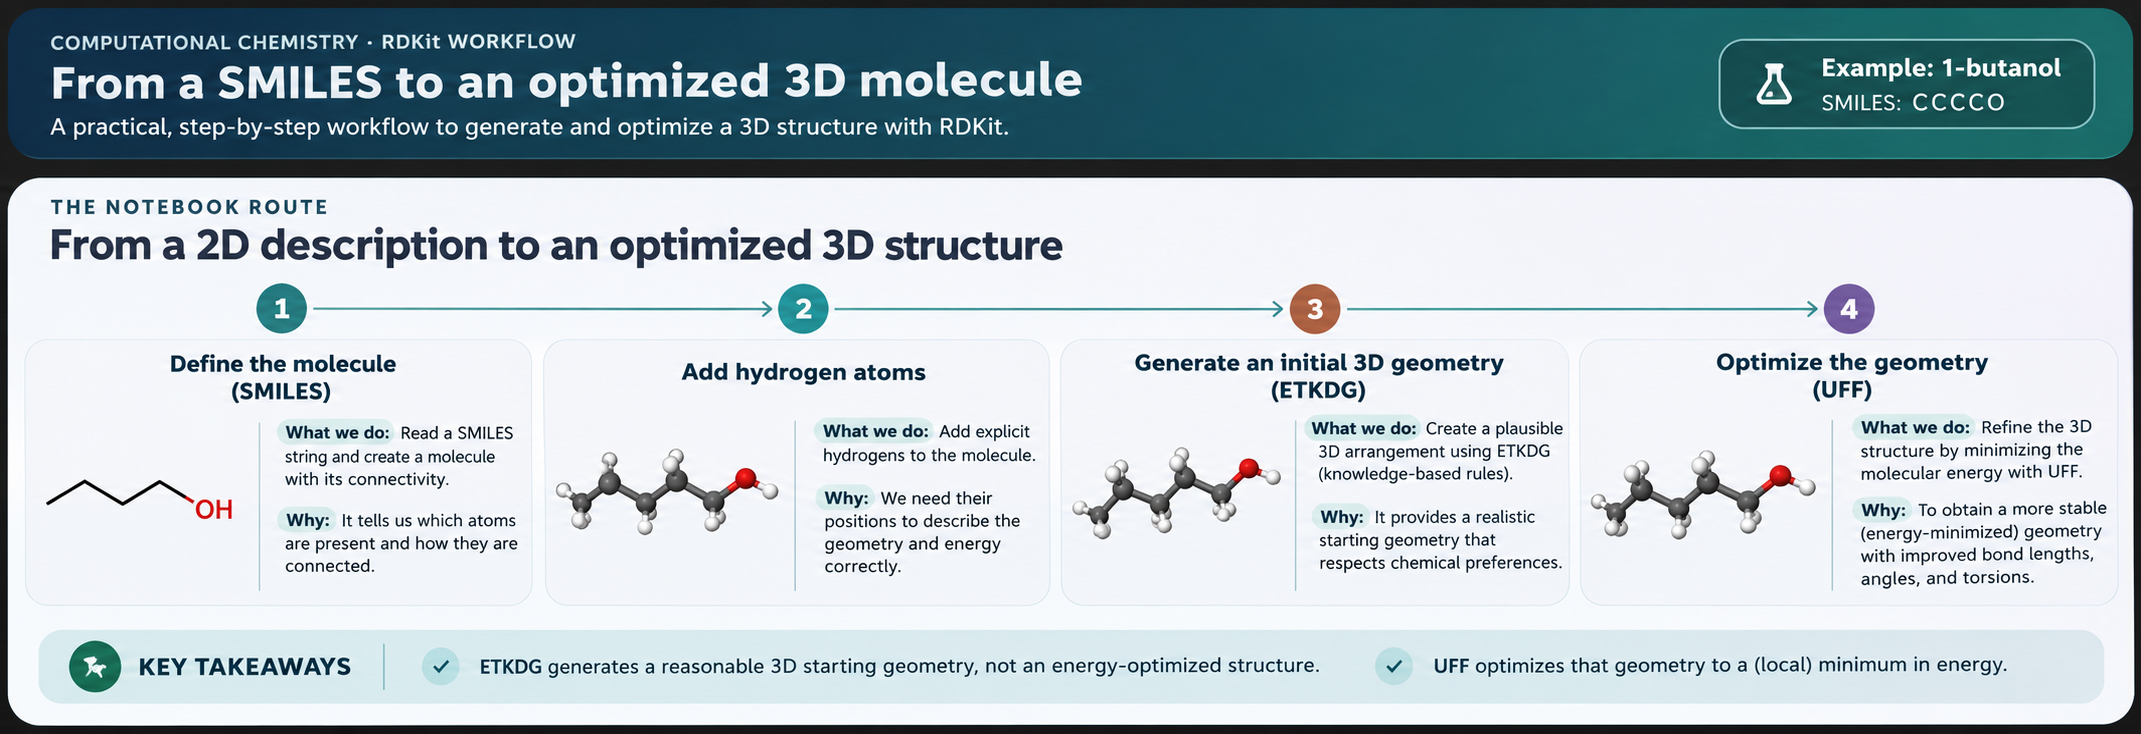

Run the viewer cell and drag the model to rotate it; scroll to zoom. Find the oxygen at one end, then turn the chain until you can see how it bends through space. Compare it with the 2D drawing: the connections are unchanged, but the positions are now visible.

**Turning the view changes the camera, not the conformation.** A different conformer would require changing the atom positions, for example by rotating bonds and generating another geometry.


In [50]:
# STEP 5 — Visualize the optimized 3D molecule
#
# The molecule already contains 3D coordinates generated by ETKDG
# and refined through UFF optimization.
#
# We now use py3Dmol to display those coordinates in an interactive viewer.
# No new conformer is generated, and the geometry is not modified.

# 1. Create an interactive 3D viewer
view = py3Dmol.view(width=640, height=420)

# 2. Transfer the molecule and its existing 3D coordinates to the viewer
view.addModel(Chem.MolToMolBlock(mol_3d), "sdf")

# 3. Display atoms and bonds using a stick representation
view.setStyle({"stick": {}})

# 4. Customize the background
view.setBackgroundColor("#f4f8fa")

# 5. Center the molecule and adjust the zoom
view.zoomTo()

# 6. Display the interactive molecular structure
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The useful distinction is between **structure** and **shape**: one connectivity graph can have several conformers. The model above is one plausible arrangement, rather than a complete picture of the shapes present in a sample.

<details>
<summary><strong>If you want to know how the shape was generated</strong></summary>

RDKit first adds explicit hydrogens, then uses ETKDG distance geometry to place the atoms. UFF adjusts those positions toward a local force-field minimum. The fixed random seed makes this example reproducible; it does not identify a uniquely correct conformation or establish the most populated shape in a solvent.

The viewer displays those existing coordinates using 3Dmol.js, which must be available to the notebook frontend. The optional coordinate table is at the end.

</details>


## Bring the workflow back to your chemistry

We started by recognizing a structure on screen. The same molecule then became a graph we could inspect, a row of properties we could compare, and a conformer we could rotate. Each representation answers a different question. Choosing one begins with deciding what you want to learn about the compound.

Return to the first viewer with a molecule you know well. Which part of this notebook would help you check, compare, or organize it?

## Suggested solutions

These are examples to compare with your own reasoning. Pay attention to the hydrogen representation when interpreting atom, bond, and degree counts.


In [51]:
# Compare both representations explicitly so the counts have a clear meaning.
exercise_mol = Chem.MolFromSmiles("CC(O)C=O")
exercise_mol_H = Chem.AddHs(exercise_mol)
print("Stored atoms (implicit H):", exercise_mol.GetNumAtoms())
print("Stored bonds (implicit H):", exercise_mol.GetNumBonds())
print("Stored atoms (explicit H):", exercise_mol_H.GetNumAtoms())
print("Stored bonds (explicit H):", exercise_mol_H.GetNumBonds())
print("Heavy atoms:", exercise_mol.GetNumHeavyAtoms())
print("Rings:", exercise_mol.GetRingInfo().NumRings())
print("Canonical SMILES:", Chem.MolToSmiles(exercise_mol))
for atom in exercise_mol_H.GetAtoms():
    print(f"Atom {atom.GetIdx()}: {atom.GetSymbol()} (degree = {atom.GetDegree()})")

Stored atoms (implicit H): 5
Stored bonds (implicit H): 4
Stored atoms (explicit H): 11
Stored bonds (explicit H): 10
Heavy atoms: 5
Rings: 0
Canonical SMILES: CC(O)C=O
Atom 0: C (degree = 4)
Atom 1: C (degree = 4)
Atom 2: O (degree = 2)
Atom 3: C (degree = 3)
Atom 4: O (degree = 1)
Atom 5: H (degree = 1)
Atom 6: H (degree = 1)
Atom 7: H (degree = 1)
Atom 8: H (degree = 1)
Atom 9: H (degree = 1)
Atom 10: H (degree = 1)


For the descriptor exercise, the same SMILES can be used without adding explicit hydrogens. Compare the calculated value with ethanol and explain the difference in terms of functional groups, rather than treating the number alone as the answer.


In [52]:
# Calculate the example property from the graph used in the exercise.
solution_mol = Chem.MolFromSmiles("CC(O)C=O")
print("Calculated logP:", round(Descriptors.MolLogP(solution_mol), 3))
print("Ethanol calculated logP:", round(Descriptors.MolLogP(descriptor_mol), 3))

Calculated logP: -0.434
Ethanol calculated logP: -0.001


## Optional appendix: look at the coordinates

The interactive model is drawn from a list of atom positions. You do not need to inspect this table to understand the main example, but it shows what was added when the graph became a 3D model.

Each row below describes one atom in the generated 1-butanol conformer, with x, y, and z in angstroms. The preview shows the first ten rows. These positions belong to this particular shape; the molecular graph still describes the same compound.


In [53]:
# Read the generated conformer without changing the molecular graph.
conformer = mol_3d.GetConformer()
coordinate_rows = []
for atom in mol_3d.GetAtoms():
    position = conformer.GetAtomPosition(atom.GetIdx())
    coordinate_rows.append({
        "Atom": atom.GetIdx(), "Element": atom.GetSymbol(),
        "x (angstrom)": position.x, "y (angstrom)": position.y, "z (angstrom)": position.z,
    })
coordinates = pd.DataFrame(coordinate_rows)
display(coordinates.head(10).round(3))


,Atom,Element,x (angstrom),y (angstrom),z (angstrom)
0,0,C,-1.471,1.064,-0.251
1,1,C,-0.828,0.061,0.706
2,2,C,0.090,-0.943,-0.011
3,3,C,1.370,-0.309,-0.572
4,4,O,2.114,0.310,0.443
5,5,H,-1.994,0.534,-1.076
6,6,H,-2.214,1.677,0.301
7,7,H,-0.707,1.747,-0.676
8,8,H,-1.639,-0.507,1.211
9,9,H,-0.265,0.606,1.494
